<a href="https://colab.research.google.com/github/priyadharshansaveetha/CSA1719/blob/main/Lab_Q_no_46.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

'image.jpg' not found. Downloading a sample image...

image 1/1 /content/image.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 373.3ms
Speed: 23.1ms preprocess, 373.3ms inference, 31.8ms postprocess per image at shape (1, 3, 640, 480)
Detected Object: bus
Confidence: 0.87
Detected Object: person
Confidence: 0.87
Detected Object: person
Confidence: 0.85
Detected Object: person
Confidence: 0.83
Detected Object: person
Confidence: 0.26
Detected Object: stop sign
Confidence: 0.26


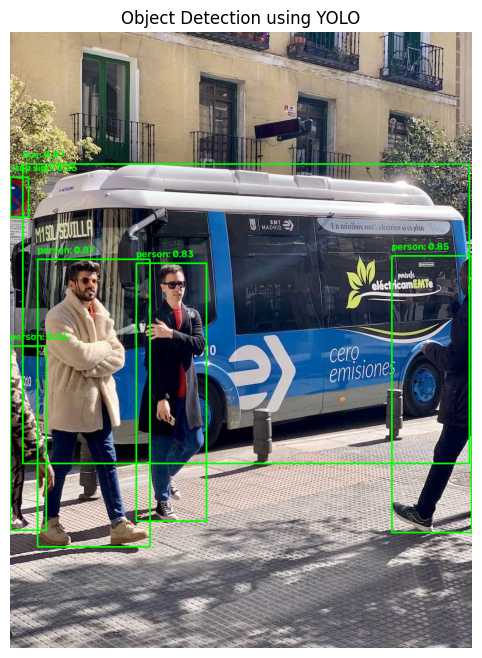

In [3]:
!pip install ultralytics

# Import required libraries
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import os
import urllib.request

# Load pre-trained YOLO model
model = YOLO("yolov8n.pt")

# Load input image
image_path = "image.jpg"

# Automatically download a sample image if it doesn't exist
if not os.path.exists(image_path):
    print(f"'{image_path}' not found. Downloading a sample image...")
    urllib.request.urlretrieve("https://raw.githubusercontent.com/ultralytics/ultralytics/main/ultralytics/assets/bus.jpg", image_path)

# Perform object detection
results = model(image_path)

# Read original image
image = cv2.imread(image_path)

# Display detected objects
for result in results:

    boxes = result.boxes

    for box in boxes:

        # Get bounding box coordinates
        x1, y1, x2, y2 = map(int, box.xyxy[0])

        # Get confidence score
        confidence = float(box.conf[0])

        # Get class ID and object name
        class_id = int(box.cls[0])
        class_name = model.names[class_id]

        # Draw bounding box
        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        # Display object name and confidence
        label = f"{class_name}: {confidence:.2f}"

        cv2.putText(
            image,
            label,
            (x1, y1 - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

        print("Detected Object:", class_name)
        print("Confidence:", round(confidence, 2))

# Convert BGR to RGB
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display final image
plt.figure(figsize=(10, 8))
plt.imshow(image)
plt.axis("off")
plt.title("Object Detection using YOLO")
plt.show()